In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
np.random.seed(42)

num_samples = 500

years_of_experience = np.random.random(size=num_samples) * 20

slope = (200_000 - 60_000) / 18
intercept = 60_000

salaries = slope * years_of_experience + intercept + np.random.normal(0, 15_000, size=num_samples)

data = {'Years_of_Experience': years_of_experience, 'Salary': salaries}
df = pd.DataFrame(data)
df.describe()

,Years_of_Experience,Salary
count,500.000000,500.000000
mean,9.971234,137668.341907
std,5.973768,49826.953891
min,0.101232,34490.166882
25%,4.825594,97379.954398
50%,10.263275,138739.343678
75%,15.122498,179794.465290
max,19.859296,241120.646240


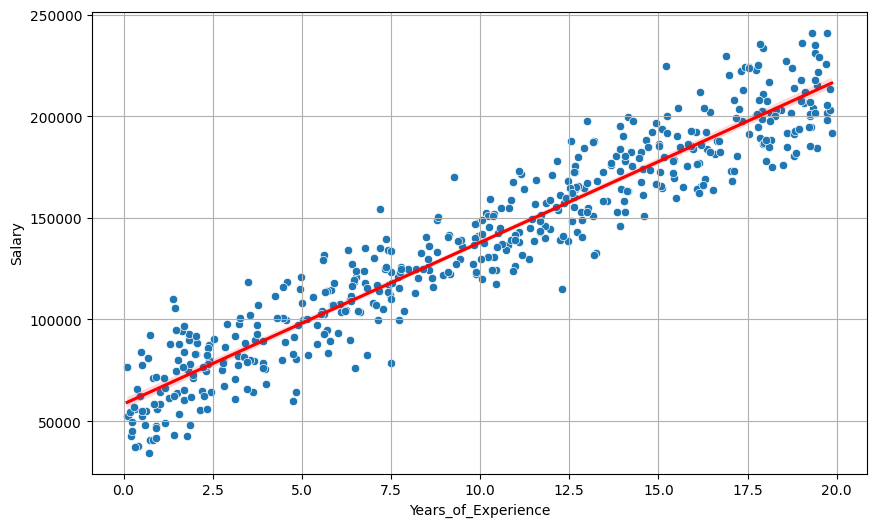

In [3]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Years_of_Experience', y='Salary', data=df)
sns.regplot(x='Years_of_Experience', y='Salary', data=df, scatter=False, color='red')
plt.grid()
plt.show()

In [4]:
X = df[['Years_of_Experience']]
y = df['Salary']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
lr = LinearRegression()

In [16]:
lr.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [8]:
lr.score(X_train, y_train)

0.9099851898062309

In [9]:
lr.score(X_test, y_test)

0.9020133966569098

In [10]:
y_pred = lr.predict(X_test)
lr.predict([[5.7]])

/Users/louisluri/Desktop/Python_Scripts/gpt-course/cuda/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([103487.13199306])

In [11]:
mean_absolute_error(y_test, y_pred)

12222.97488457372

In [12]:
mean_squared_error(y_test, y_pred)

234948851.4418914

In [13]:
r2_score(y_test, y_pred)

0.9020133966569098

In [17]:
lr.coef_

array([7950.28124495])

In [18]:
lr.intercept_

58394.22530224595

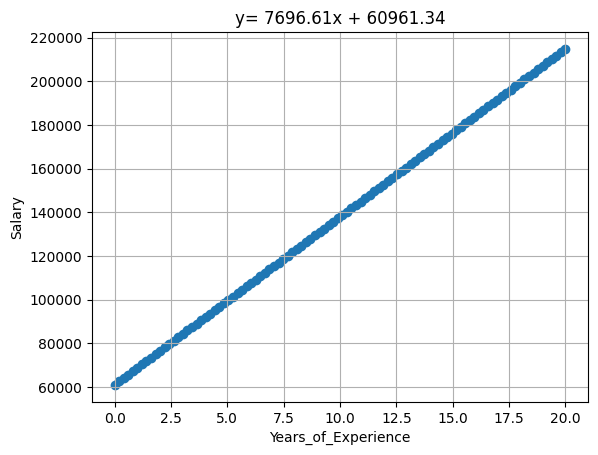

In [33]:
coefficients = lr.coef_
intercept = lr.intercept_

X = np.linspace(0, 20, 100)
y = coefficients*X + intercept

plt.scatter(X, y, label=f'y= {coefficients[0]}x + {intercept}')
plt.xlabel('Years_of_Experience')
plt.ylabel('Salary')
plt.title(f'y= {coefficients[0]:.2f}x + {intercept:.2f}')
plt.grid()